# GDP and Life Expectancy Portfolio Project


For this project, I have analysed data on GDP and life expectancy from the World Health Organization and the World Bank to try and identify the relationship between the GDP and life expectancy of six countries. 

The data includes: 
- `Country`: Chile, China, United States of America, Germany, Mexico and Zimbabwe were chosen from the World Health Organization
- `Year`: the years from 2000 - 2015 
- `LEBY`: the life expectancy per year for each country
- `GDP`: the gross domestic product of each country in a specific year 

## 1. Research Questions / Objectives 

- Has life expectancy increased over time in the six nations?
- What is the average life expectancy in these nations?
- What is the distribution of that life expectancy?
- Has GDP increased over time in the six nations?
- Is there a correlation between GDP and life expectancy of a country?


## Data Source 


## 3. Data Loading & Cleaning 

### 3.1 Importing Libraries

In [654]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import statsmodels
import math
from scipy import stats
import statsmodels.api as sm
from scipy.stats import pearsonr


### 3.2 Loading the Dataset

In [655]:
#Load data file

df = pd.read_csv('all_data.csv')

### 3.3 Initial data inspection

In [656]:
#Read data file 
df.head() 

,Country,Year,Life expectancy at birth (years),GDP
0,Chile,2000,77.3,7.786093e+10
1,Chile,2001,77.3,7.097992e+10
2,Chile,2002,77.8,6.973681e+10
3,Chile,2003,77.9,7.564346e+10
4,Chile,2004,78.0,9.921039e+10


In [657]:
df.shape

(96, 4)

In [658]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96 entries, 0 to 95
Data columns (total 4 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Country                           96 non-null     object 
 1   Year                              96 non-null     int64  
 2   Life expectancy at birth (years)  96 non-null     float64
 3   GDP                               96 non-null     float64
dtypes: float64(2), int64(1), object(1)
memory usage: 3.1+ KB


First, it is important to explore the countries that are in the dataset. There are six countries represented in the dataset: Chile, China, Germany, Mexico, United States of America and Zimbabwe. 

In [659]:
print(df.Country.unique())

['Chile' 'China' 'Germany' 'Mexico' 'United States of America' 'Zimbabwe']


Next, it is important to explore the range of years represented in the dataset. The years range from 2000 to 2015. 

In [660]:
print(df.Year.unique())

[2000 2001 2002 2003 2004 2005 2006 2007 2008 2009 2010 2011 2012 2013
 2014 2015]


### 3.4 Column Renaming 

All column headers start with one words apart from `Life expectancy at birth (years)`. Although there is nothing wrong with the header, it will be easier to plot graphs and charts later if the header was also one word. 

In [661]:
df.rename(columns={'Life expectancy at birth (years)' : 'LEBY'}, inplace=True)

### 3.5 Data Type Validation

In [662]:
#Check for data types
df.dtypes

Country     object
Year         int64
LEBY       float64
GDP        float64
dtype: object

### 3.6 Missing Values Checks 

In [663]:
#Check for missing values 
df.isnull().sum()



Country    0
Year       0
LEBY       0
GDP        0
dtype: int64

In [664]:
#Check for duplicate values 
df.duplicated().sum()



np.int64(0)

### 3.7 Defining the Analysis Scope 

The dataset contains GDP per capita and life expectancy data for six countries over the period 2000–2015. As the dataset is already limited in scope and complete, no additional country or year filtering was applied. All six countries contain observations across the full time range, with no systematic gaps in the key variables.



In [665]:
#Defining analysis scope 
df[['Country', 'Year']].nunique()
df.isna().sum()

Country    0
Year       0
LEBY       0
GDP        0
dtype: int64

In [666]:
# Country names were standardised to ensure consistency across years.
df['Country'] = df['Country'].str.strip()

### 3.8 Inspecting Outliers

In [667]:
# Inspecting outliers in life expectancy dataset using IQR range 

Q1 = np.percentile(df['LEBY'], 25, interpolation='midpoint') 
Q2 = np.percentile(df['LEBY'], 50, interpolation='midpoint') 
Q3 = np.percentile(df['LEBY'], 75, interpolation='midpoint') 

print('Q1:', Q1)
print('Q2:', Q2)
print('Q3:', Q3)

IQR = Q3 - Q1 
print('IQR:', IQR)

#Find lower and upper limits 
low_lim = Q1 = 1.5 * IQR 
up_lim = Q3 + 1.5 * IQR 
print('Lower limit:', low_lim)
print('Upper limit:', up_lim)

#Filtering out outliers 
outlier = [] 
for i in df['LEBY']: 
    if ((i>up_lim) or (i<low_lim)):
        outlier.append(i)
print('Outliers in life expectancy dataset:', outlier)

Q1: 74.45
Q2: 76.75
Q3: 78.9
IQR: 4.450000000000003
Lower limit: 6.675000000000004
Upper limit: 85.57500000000002
Outliers in life expectancy dataset: []


In [668]:
# Inspecting outliers in GDP dataset using IQR range 

Q1 = np.percentile(df['GDP'], 25, interpolation='midpoint') 
Q2 = np.percentile(df['GDP'], 50, interpolation='midpoint') 
Q3 = np.percentile(df['GDP'], 75, interpolation='midpoint') 

print('Q1:', Q1)
print('Q2:', Q2)
print('Q3:', Q3)

IQR = Q3 - Q1 
print('IQR:', IQR)

#Find lower and upper limits 
low_lim = Q1 = 1.5 * IQR 
up_lim = Q3 + 1.5 * IQR 
print('Lower limit:', low_lim)
print('Upper limit:', up_lim)

#Filtering out outliers 
outlier = [] 
for i in df['GDP']: 
    if ((i>up_lim) or (i<low_lim)):
        outlier.append(i)
print('Outliers in GDP dataset:', outlier)

Q1: 172997500000.0
Q2: 1280220000000.0
Q3: 4244410000000.0
IQR: 4071412500000.0
Lower limit: 6107118750000.0
Upper limit: 10351528750000.0
Outliers in GDP dataset: [77860932152.0, 70979923960.0, 69736811435.0, 75643459840.0, 99210392858.0, 122965000000.0, 154788000000.0, 173606000000.0, 179638000000.0, 172389000000.0, 218538000000.0, 252252000000.0, 267122000000.0, 278384000000.0, 260990000000.0, 242518000000.0, 1211350000000.0, 1339400000000.0, 1470550000000.0, 1660290000000.0, 1955350000000.0, 2285970000000.0, 2752130000000.0, 3552180000000.0, 4598210000000.0, 5109950000000.0, 6100620000000.0, 10482400000000.0, 11064700000000.0, 1949950000000.0, 1950650000000.0, 2079140000000.0, 2505730000000.0, 2819250000000.0, 2861410000000.0, 3002450000000.0, 3439950000000.0, 3752370000000.0, 3418010000000.0, 3417090000000.0, 3757700000000.0, 3543980000000.0, 3752510000000.0, 3890610000000.0, 3375610000000.0, 683648000000.0, 724704000000.0, 741560000000.0, 713284000000.0, 770268000000.0, 866346000

## 4. Exploratory Data Analysis (EDA) & Data Visualisation 

This section focuses on understanding the dataset and exploring patterns across the countries over time. Visualisations are used alongside high-level descriptive statistics to understand patterns and relationships over time.


### 4.1 Dataset Overview

- 6 countries, 16 years each -> 96 observations 
- Variables: 
    - `Year`: 2000 - 2015 
    - `LEBY`: Life expectancy at birth (years)
    - `GDP`: Total GDP per country

### 4.2 Summary Statistics 

Life expectancy is relatively consistent across countries (44–81 years), while GDP varies much more widely (4.4 billion to 18.1 trillion USD), reflecting substantial economic differences between countries.


In [669]:
df.describe()

,Year,LEBY,GDP
count,96.000000,96.000000,9.600000e+01
mean,2007.500000,72.789583,3.880499e+12
std,4.633971,10.672882,5.197561e+12
min,2000.000000,44.300000,4.415703e+09
25%,2003.750000,74.475000,1.733018e+11
50%,2007.500000,76.750000,1.280220e+12
75%,2011.250000,78.900000,4.067510e+12
max,2015.000000,81.000000,1.810000e+13


The `GDP` histogram exhibited a right-skewed distribution, with most GDP values clustered at the lower end and a long tail extending towards the highest values. This skewness indicates that while many countires have lower to moderate GDP, a small number of countries have very large GDP figures that stretch the distribution to the the right. The extreme values influence the mean of the dataset, meaning that the average is influenced. As a result, the median can provide a more representative measure of central tendency for GDP in this dataset. 

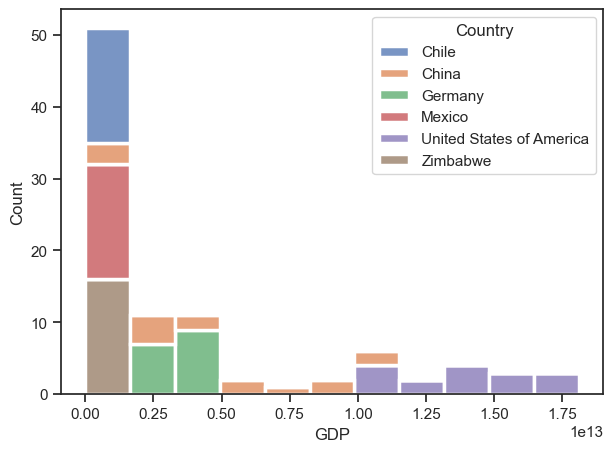

In [670]:
plt.figure(figsize=(7, 5))

sns.histplot(
    df,
    x="GDP", hue="Country", linewidth=2.5, multiple='stack')
plt.show()

The `LEBY` histogram exhibited a left-skewed distribution, with most values clustered at the higher end and a long tail extending towards lower values. This skewness indicates that while many countries have relatively high life expectancy, a smaller number have substantially lower life expectancy. For the left‑skewed life expectancy distribution, the mean is typically less than the median due to a few lower values, so the median again may better represent the central tendency. 

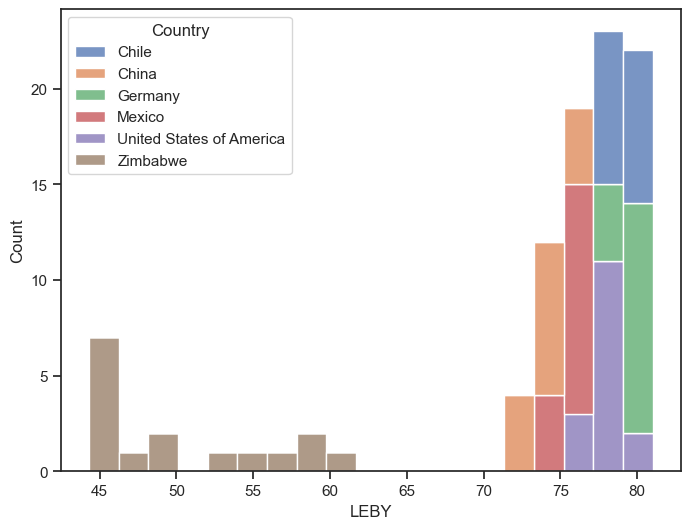

In [671]:
#Visualisation of life expectancy to see general distribution
plt.figure(figsize=(8,6))
sns.histplot(df, x='LEBY', hue='Country', multiple='stack')
plt.show()

### 4.3 Has life expectancy increased over time in the six nations?



Life expectancy increased over time across all six countries between 2000 and 2015. While most countries show a gradual and steady upward trend, Zimbabwe exhibits a more pronounced increase in life expectancy over the period. The average life expectancy across the other five countries ranges between approximately 70 and 85 years, whereas Zimbabwe’s life expectancy remains lower, ranging from around 45 to 60 years.

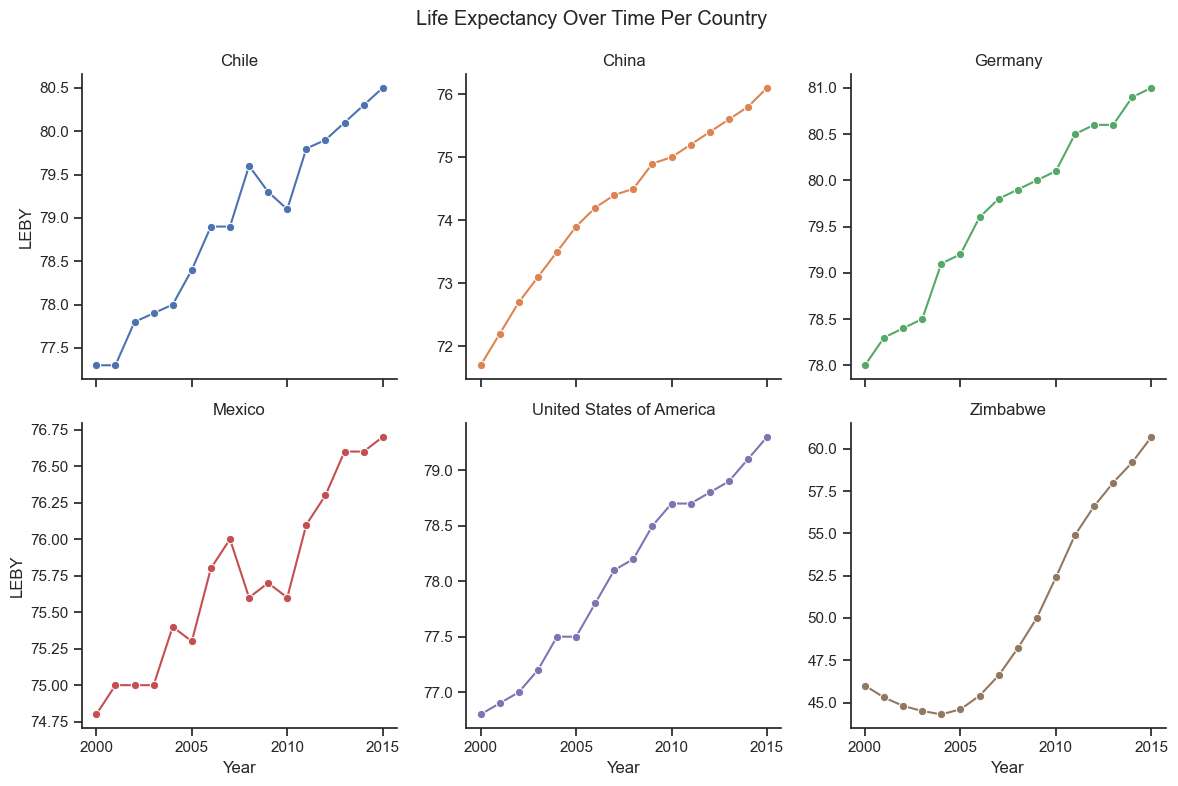

In [672]:
#Visualisation of Life expectancy over time for each country 
sns.set_theme(style="ticks")
g = sns.FacetGrid(df, col="Country", col_wrap=3, hue='Country', height=4, sharey=False)
g.map(sns.lineplot, "Year", "LEBY", marker="o")
g.set_titles("{col_name}")
g.set_axis_labels("Year", "LEBY")
plt.subplots_adjust(top=0.9)
g.fig.suptitle('Life Expectancy Over Time Per Country')
plt.show()

Figure 1. The line graphs show the life expectancy over time for each country. 

### 4.4 What is the average life expectancy in these nations?

                    Country      LEBY
0                     Chile  78.94375
1                     China  74.26250
2                   Germany  79.65625
3                    Mexico  75.71875
4  United States of America  78.06250
5                  Zimbabwe  50.09375


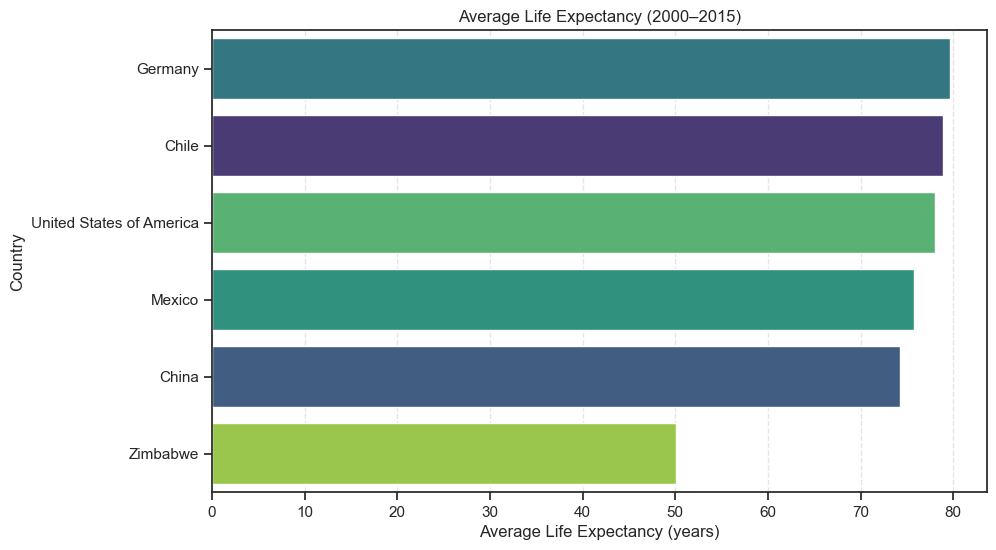

In [673]:
#Filter the years 2000 to 2015 for each country 
filtered_df = df[(df['Year'] >= 2000) & (df['Year'] <= 2015)]

#Group by country and calculate the average LEBY for each country 
average_leby = filtered_df.groupby('Country'). LEBY.mean().reset_index()
print(average_leby)

#Visualisation of average life expectancy between 2000 and 2015 
plt.figure(figsize=(10,6))
sns.barplot(
    x='LEBY',
    y='Country',
    data=average_leby,
    hue = 'Country',
    palette='viridis', 
    order=average_leby.sort_values('LEBY', ascending=False).Country
)
plt.xlabel('Average Life Expectancy (years)')
plt.ylabel('Country')
plt.title('Average Life Expectancy (2000–2015)')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.show()




The bar chart illustrates the average life expectancy at birth (`LEBY`) for six countries over the period 2000 to 2015.



Germany has the highest average life expectancy at approximately 79.7 years, closely followed by Chile (78.9 years) and the United States (78.1 years). These countries show relatively high and similar life expectancy levels, indicating strong and stable health outcomes over the period.

Mexico and China have moderately lower average life expectancy values, at around 75.7 years and 74.3 years respectively. While lower than Germany and Chile, these figures still suggest steady improvements in population health over time.

In contrast, Zimbabwe has a significantly lower average life expectancy of approximately 50.1 years, standing out clearly from the other countries. This highlights substantial disparities in health outcomes between Zimbabwe and the other countries included in the analysis.

Overall, the bar chart demonstrates clear differences in average life expectancy across countries, with higher-income countries generally exhibiting higher life expectancy than lower-income countries.

### 4.5 What is the distribution of that life expectancy?

In [674]:
#Distribution of life expectancy for each country between 2000 and 2015
country_distribution = df.groupby('Country').LEBY.median().sort_values().reset_index()
print(country_distribution)

                    Country   LEBY
0                  Zimbabwe  47.40
1                     China  74.45
2                    Mexico  75.65
3  United States of America  78.15
4                     Chile  79.00
5                   Germany  79.85


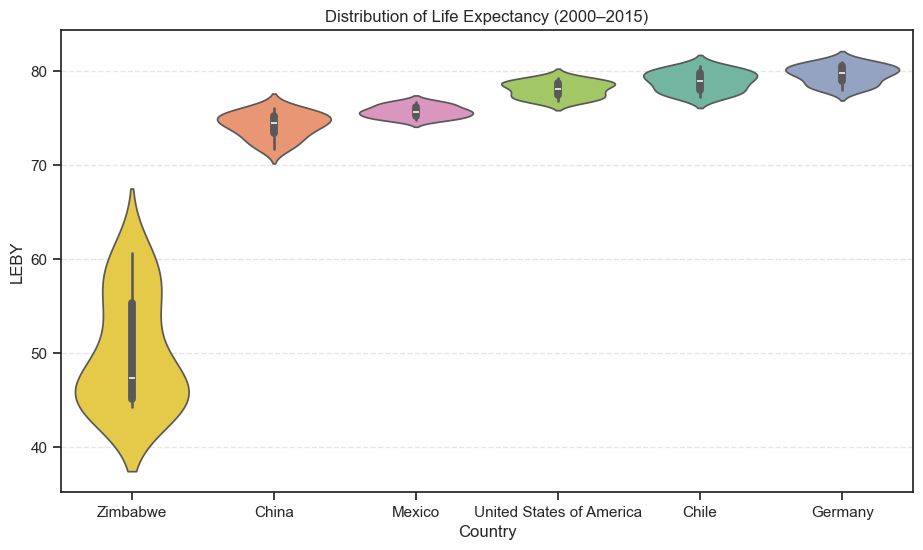

In [675]:
#Visualisation of distribution of life expectancy per country
plt.figure(figsize=(11, 6))
sns.violinplot(
    x='Country', 
    y='LEBY', 
    data=df, 
    hue='Country',
    palette='Set2',
    order=country_distribution['Country'].values
)
plt.title('Distribution of Life Expectancy (2000–2015)')
plt.xlabel('Country')
plt.ylabel('LEBY')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

The violin plot shows the distribution of life expectancy from 2000 - 2015 for six countries. Germany, Chile and the USA have high and stable life expectancy, with values clustered narrowly 78-80 years. Mexico and China show slightly more variation, with life expectancy generally between 74-76 years. Zimbabwe is a clear outlier, with lower and more variable life expectancy ranging roughly from 45 to 60 years. The plot highlights substantial differences in health outcomes between countries, with higher-income countries achieving consistent and high life expectancy, while Zimbabwe's lower and more variable values indicate ongoing challenges. 

### 4.6 Outliers Visualisation & Interpretation

Using the interquartile range (IQR) method, we calculated the lower and upper bounds for potential outliers in the life expectancy variable. Based on these bounds, no life expectancy values fell outside the expected range, so no statistical outliers were detected in the dataset. This suggests that life expectancy values are relatively consistent without extreme deviations according to the applied method. 

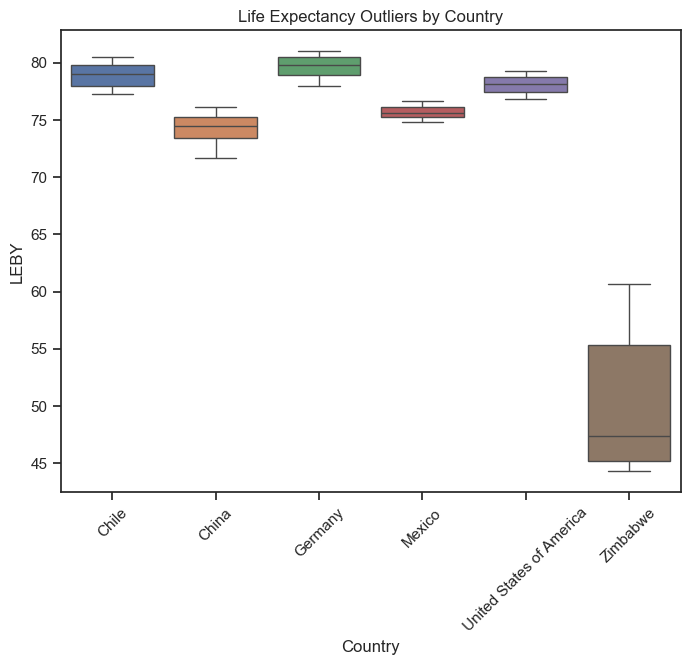

In [676]:
#Visualisation of life expectancy outliers using boxplot 
plt.figure(figsize=(8,6)) 
sns.boxplot(x='Country', y='LEBY', data=df, hue='Country')
plt.title('Life Expectancy Outliers by Country') 
plt.xticks(rotation=45)
plt.xlabel('Country')
plt.ylabel('LEBY') 
plt.show() 

### 4.7 Has GDP increased over time in the six nations?

 


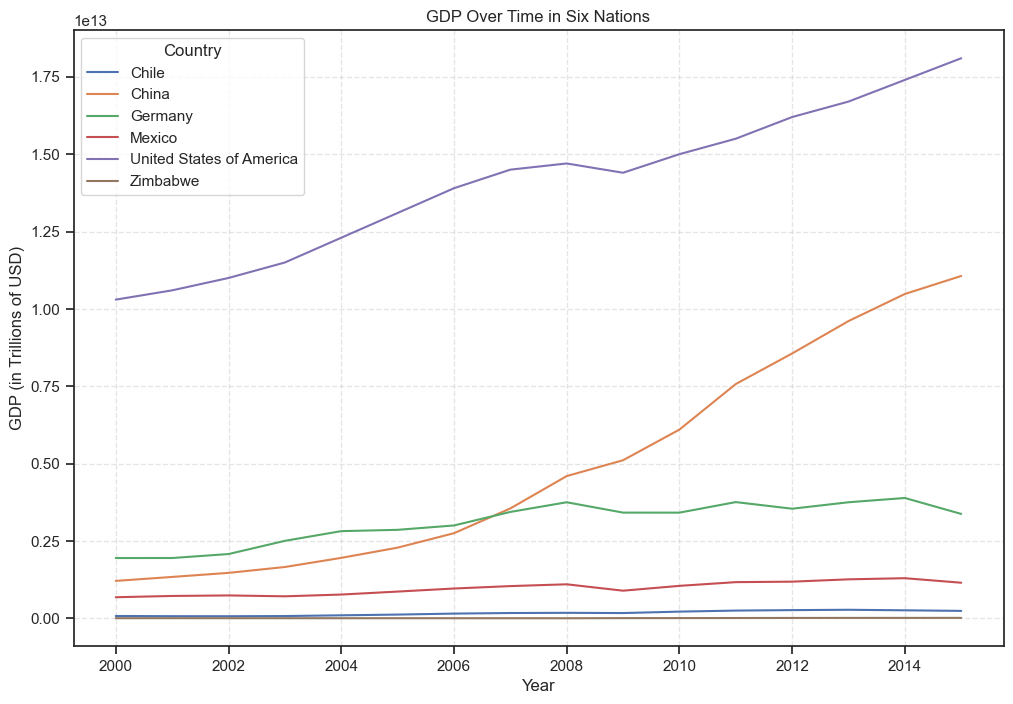

In [696]:
#Visualisation of GDP over time in six nations 
plt.figure(figsize=(12, 8))
sns.lineplot(data=df, x='Year', y='GDP', hue='Country')
plt.grid(True, linestyle='--', alpha=0.5)
plt.title('GDP Over Time in Six Nations')
plt.xlabel('Year')
plt.ylabel('GDP (in Trillions of USD)')
plt.legend(title='Country')
plt.show()


`GDP` trends vary across the six countries between 2000 and 2015. China exhibits a strong and consistent increase in GDP throughout the period. The United States begins with a substantially higher GDP than the other countries and shows an overall upward trend, with a noticeable decline in 2009. A similar decline in 2009 is also observed for Mexico and Germany. Germany’s GDP remains relatively stable over the period, displaying moderate fluctuations rather than sustained growth. Chile’s GDP remains largely stable, with a modest increase observed from around 2006 onwards. Zimbabwe’s GDP shows relatively little change over the period compared to the other countries.

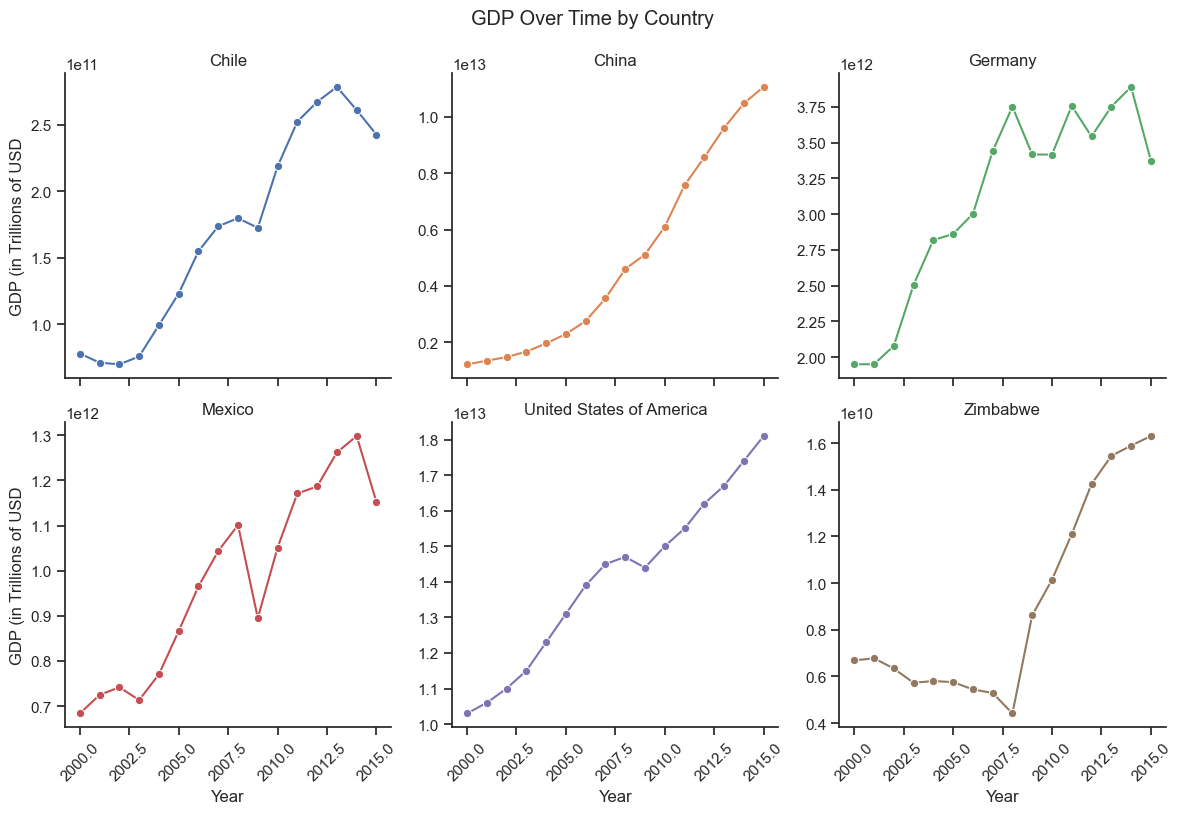

In [704]:
#Visualisation of GDP over time for each country 
sns.set_theme(style="ticks")
g = sns.FacetGrid(df, col="Country", col_wrap=3, hue='Country', height=4, sharey=False)
g.map(sns.lineplot, "Year", "GDP", marker="o")
g.set_titles("{col_name}")
g.tick_params(axis='x', rotation=45)
g.set_axis_labels("Year", "GDP (in Trillions of USD")
plt.subplots_adjust(top=0.9)
g.fig.suptitle('GDP Over Time by Country')
plt.show()

Figure 2. The line graphs show the GDP over time for each country. 

### 4.8 Is there a correlation between GDP and life expectancy of a country?

The scatter plot shows a clear positive relationship between GDP and life expectancy across the six countries from 2000 to 2015.

For China and the USA, GDP values are widely spread, indicating substantial variation in wealth over the period. Life expectancy, while more consistent than GDP, has gradually increased, forming an upward trend. This suggests that despite large changes in GDP over time, life expectancy has improved steadily.

For Chile, Germany, and Mexico, the points are tightly clustered, indicating that both GDP and life expectancy are relatively stable. Life expectancy in these countries shows gradual increases, but overall variation in GDP is minimal compared to China and the USA.

For Zimbabwe, GDP levels remain low and show limited variation, yet life expectancy increases steadily over time. This indicates that improvements in health outcomes have occurred despite relatively weak economic growth, suggesting that factors beyond GDP may have played a significant role.


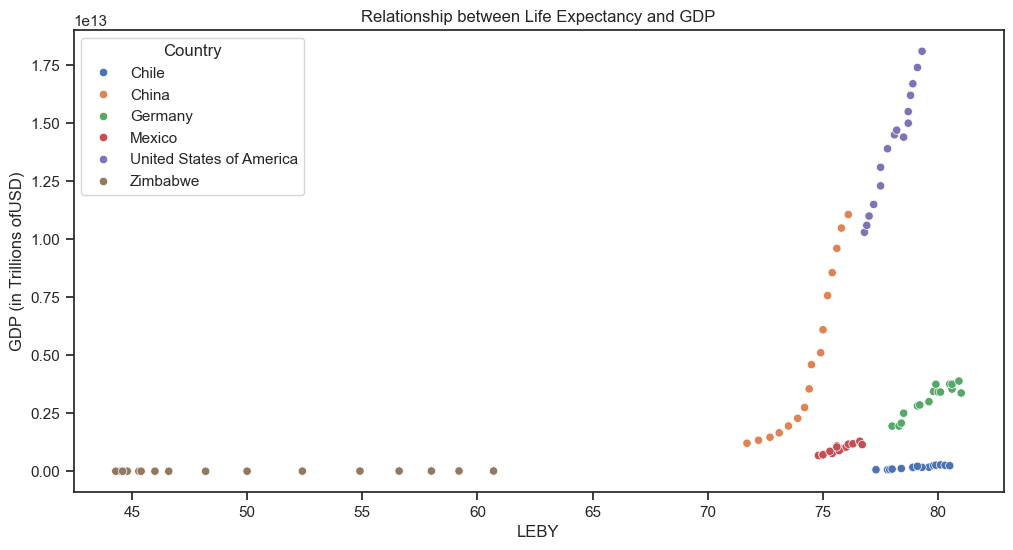

In [711]:
#Relationship between Life Expectancy and GDP 
plt.figure(figsize=(12, 6)) 
sns.scatterplot(data=df, x='LEBY', y='GDP', hue='Country')
plt.title('Relationship between Life Expectancy and GDP')
plt.xlabel('LEBY')
plt.ylabel('GDP (in Trillions ofUSD)')
plt.legend(title='Country')
plt.show()

Using the IQR method (values above Q3 + 1.5×IQR flagged as outliers), many GDP values were identified as outliers. This is expected given the wide differences in the sizes of national economies — the largest economies have GDP figures much higher than the central spread of the dataset. These outliers do not necessarily indicate errors; rather, they reflect the real variation among countries. Because outliers can heavily influence measures like the mean, we also consider robust statistics such as the median to summarise central tendency.

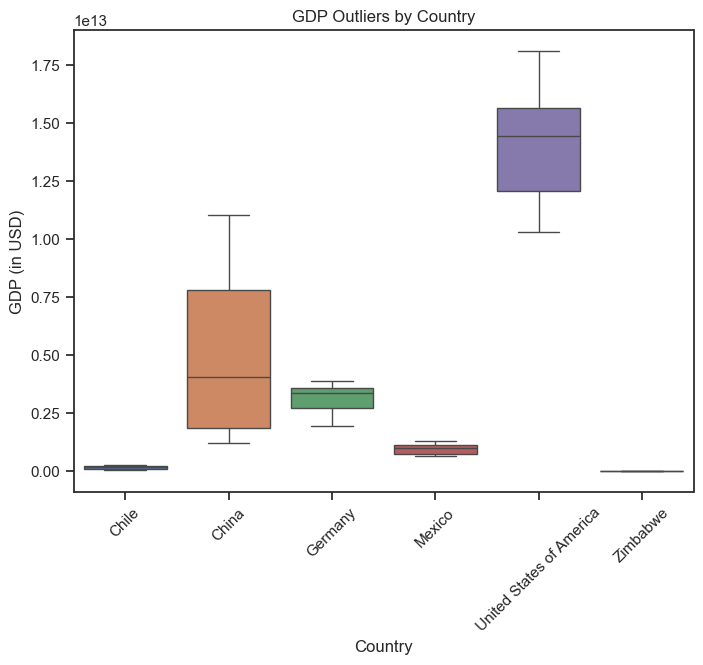

In [712]:
#Visualisation of outliers for GDP using boxplot 
plt.figure(figsize=(8, 6)) 
sns.boxplot(x='Country', y='GDP', data=df, hue='Country', showfliers=True)
plt.title('GDP Outliers by Country') 
plt.xticks(rotation=45)
plt.xlabel('Country')
plt.ylabel('GDP (in USD)') 
plt.show() 

## 5. Summary of Visual Insights 

The visual explorations of `GDP` and life expectancy (`LEBY`) helped reveal how these variables behave across the dataset and what that means for interpretation. The `GDP` histogram showed a right‑skewed distribution, where most values are clustered at the lower and middle range and a long tail extends toward higher GDP values. This indicates that while many countries in the sample have relatively smaller or moderate GDPs, a few have very large economies, stretching the distribution to the right. The summary statistics support this, with a mean GDP (~3.88 × 10¹²) much higher than the median GDP (~1.28 × 10¹²), reflecting the influence of these large values on the average. In contrast, the life expectancy (`LEBY`) histogram exhibited a left‑skewed distribution, with most countries having higher life expectancy and a tail toward lower values. The summary statistics show the mean life expectancy (~72.79) is lower than the median (~76.75), consistent with the left skew and a few countries with lower life expectancy pulling the average down. Boxplots further illustrate these patterns — GDP has a wide spread with several statistically identified extremes, while life expectancy is more tightly distributed with no outliers flagged by the IQR method. Scatter and bivariate visualisations suggest a positive relationship between GDP and life expectancy, laying the groundwork for later correlation and regression analysis. Together, these plots provide a clear picture of distribution shape, variability, central tendency and potential associations, which informed subsequent hypothesis tests and interpretation. 



## 6. Hypothesis Testing / Statistical Analysis 

To investigate whether there is a statistically significant linear relationship between GDP and life expectancy, a Pearson correlation test was conducted. The Pearson correlation coefficient (denoted r) measures the strength and direction of a linear association between two continuous variables. It ranges from −1 (perfect negative relationship) to +1 (perfect positive relationship), with values near 0 indicating little or no linear association



### 6.1 Hypothesis 

We set up the following hypotheses:

	•	Null hypothesis (H₀): There is no linear relationship between GDP and life expectancy (ρ = 0)

	•	Alternative hypothesis (H₁): There is a linear relationship between GDP and life expectancy (ρ ≠ 0)

### 6.2 Pearson correlation test

A Pearson correlation test showed a statistically significant, positive linear relationship between GDP and life expectancy, r = 0.343, p = 0.001. This indicates that countries with higher GDP tend to have higher life expectancy, and the likelihood that this pattern is due to random sampling is very low.

In [713]:
#drop any missing values
df_clean = df[['GDP', 'LEBY']].dropna()

# calculate Pearson correlation and p-value
corr, p_value = pearsonr(df_clean['GDP'], df_clean['LEBY'])

print(f"Pearson correlation coefficient (r): {corr:.3f}")
print(f"P-value: {p_value:.3f}")

# optional interpretation
alpha = 0.05
if p_value < alpha:
    print("The correlation is statistically significant (reject H0 at alpha = 0.05)")
else:
    print("The correlation is not statistically significant (fail to reject H0 at alpha = 0.05)")

Pearson correlation coefficient (r): 0.343
P-value: 0.001
The correlation is statistically significant (reject H0 at alpha = 0.05)


## 6.3 Linear Regression 

To go beyond correlation and model the relationshipi between GDP and LEBY, we use simple linear regression. Linear regression gives us a predictive equation that describes how life expectancy changes, on average, with changes in GDP. 

In [714]:
# Define predictor and response
X = df_clean['GDP']
y = df_clean['LEBY']

# Add constant term for intercept
X = sm.add_constant(X)

# Fit the regression model
model = sm.OLS(y, X).fit()

# Output model summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                   LEBY   R-squared:                       0.118
Model:                            OLS   Adj. R-squared:                  0.108
Method:                 Least Squares   F-statistic:                     12.55
Date:                Tue, 13 Jan 2026   Prob (F-statistic):           0.000619
Time:                        13:52:01   Log-Likelihood:                -357.00
No. Observations:                  96   AIC:                             718.0
Df Residuals:                      94   BIC:                             723.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         70.0548      1.286     54.474      0.0

Key results from the regression output:

	•	The intercept (constant) is about 70.05, which represents the predicted life expectancy when GDP is zero (a baseline reference point in the model).
	
	•	The GDP coefficient is 7.048 × 10⁻¹³, meaning that as GDP increases, predicted life expectancy increases by a very small amount on average. The positive coefficient shows the direction of the relationship: higher GDP is associated with higher life expectancy. 

The R‑squared value of 0.118 indicates that around 11.8 % of the variation in life expectancy can be explained by GDP. In simple regression, R‑squared tells us how much of the differences in life expectancy values can be accounted for by differences in GDP — a relatively small portion, which tells us there are likely other factors affecting life expectancy not captured here.

The p‑value for the GDP coefficient is 0.001, which is less than the commonly used significance level of 0.05. This means we can conclude that the relationship between GDP and life expectancy is statistically significant — the association found in the sample is unlikely to be due to random chance alone. A low p‑value like this tells us that the slope (the effect of GDP on life expectancy) is likely meaningful rather than something that just appeared by accident.

### Predicting Life Expectancy Using the Trained Model 



In [715]:

# Define features (X) and target (y)
# Here GDP is the feature and LEBY (life expectancy) is the target
X = df[['GDP']]   # features must be 2D, so double brackets
y = df['LEBY']    # target is 1D

# 2) Split into training and test sets
from sklearn.model_selection import train_test_split

train_X, test_X, train_y, test_y = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train the model 
from sklearn.linear_model import LinearRegression

# Create the model
lr = LinearRegression()

# Fit the model to your training data (GDP -> Life Expectancy)
lr.fit(train_X, train_y)  # model learns from data

# Predict on test set 
test_predictions = lr.predict(test_X)

print("Predicted life expectancy (test data):")
print(test_predictions)


# Define a realistic GDP range based on your dataset
min_gdp = df['GDP'].min()
max_gdp = df['GDP'].max()

# Generate random GDP values within that range
# Here we generate 10 random values (change size=10 to any number you want)
random_gdp_values = np.random.uniform(min_gdp, max_gdp, size=10)

# Convert the random values into a DataFrame with the same column name used during training
random_gdp_df = pd.DataFrame({"GDP": random_gdp_values})

# 3) Predict life expectancy for these random GDP values
random_predictions = lr.predict(random_gdp_df)

# Print the random GDP values and corresponding predictions
print("Random GDP values:")
print(random_gdp_df)
print("\nPredicted life expectancy for these random GDP values:")
print(random_predictions)


Predicted life expectancy (test data):
[70.11939553 82.68152613 80.95071898 70.12631958 71.58227376 83.73506091
 79.97243667 72.6858063  70.17295345 70.27881644 77.8653671  78.00262763
 71.22098658 70.18901945 78.44082285 74.7052293  70.31537711 72.18540738
 70.76630806 70.11869211]
Random GDP values:
            GDP
0  8.814627e+12
1  1.393054e+13
2  1.060494e+13
3  7.830985e+12
4  1.554758e+13
5  1.119207e+12
6  1.096391e+13
7  8.250541e+12
8  5.341790e+12
9  6.246803e+12

Predicted life expectancy for these random GDP values:
[76.74758734 80.59743643 78.09483934 76.00737168 81.8143019  70.95659188
 78.36497224 76.32309811 74.13419057 74.81523574]




After training a linear regression model using GDP to predict life expectancy, we applied the model to the test set and to a series of randomly generated GDP values within the observed range. The predicted life expectancy for the test data helps us understand how well the model generalises to unseen examples, while the predictions for random GDP values illustrate how life expectancy is expected to change across different GDP levels according to the model.

Overall, these predictions show that higher GDP values generally correspond to higher predicted life expectancy, consistent with the positive relationship observed earlier in our correlation and regression analysis. However, because the regression model explains only part of the variation in life expectancy, these predictions are approximate and should be interpreted as estimates rather than precise forecasts.


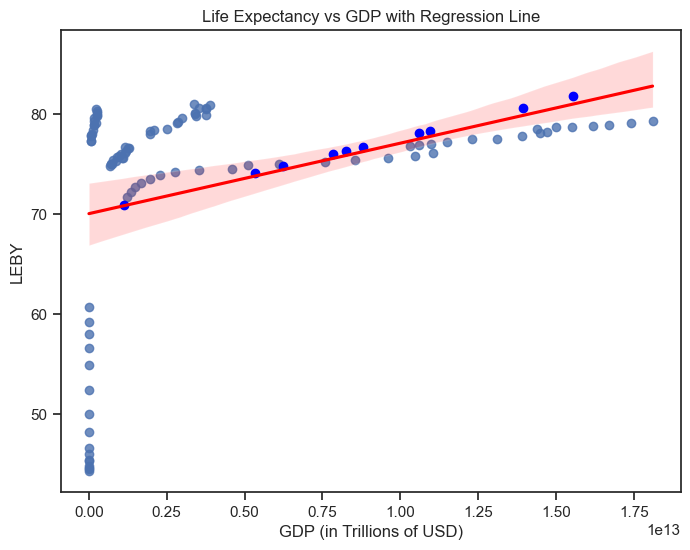

In [716]:
#Visualisation of regression line and predictive data points 
plt.figure(figsize=(8,6))
sns.regplot(x='GDP', y='LEBY', data=df, line_kws={"color": "red"})

# Overlay random predictions
plt.scatter(random_gdp_df['GDP'], random_predictions, color='blue', label='Random Sample Predictions')

plt.title('Life Expectancy vs GDP with Regression Line')
plt.xlabel('GDP (in Trillions of USD)')
plt.ylabel('LEBY')
plt.show()


Each dot represents a GDP–life expectancy pair from the dataset, with the fitted regression line (red) showing the overall linear trend that higher GDP is associated with higher life expectancy. Blue points show predicted life expectancy values for randomly sampled GDP values within the observed range, illustrating how the trained model estimates outcomes across different economic levels. The plot visualises the positive relationship between GDP and life expectancy identified through correlation and regression analysis.

## 7. Results & Key Insights 

### 7.1 Summary of Main Findings
The exploratory analysis showed that the distribution of GDP is heavily right‑skewed, meaning most countries have relatively lower GDP values while a few have very high values. In contrast, life expectancy is more tightly distributed with no major outliers, indicating relative consistency across countries for life expectancy. These characteristics helped inform the choice of statistical methods used later. 

### 7.2 Correlation Results

A Pearson correlation test was conducted to measure the linear association between GDP and life expectancy. The analysis produced a moderate positive correlation with a coefficient of r = 0.343 and a p‑value = 0.001, which is below the typical significance threshold of 0.05. This means there is statistical evidence of a positive linear relationship between GDP and life expectancy in this dataset — higher GDP tends to be associated with higher life expectancy.

### 7.3 Regression Model Results 

A simple linear regression model was then fitted to further quantify this relationship. The model can be written as:

`Predicted Life Expectancy = 70.055 + (7.048 × 10⁻¹³) × GDP`

The slope term is positive, reinforcing that predicted life expectancy increases with GDP. The R‑squared value of 0.118 indicates that about 11.8 % of the variation in life expectancy is explained by GDP alone, suggesting that although GDP is a significant predictor, many other factors (e.g., healthcare, education, demographics) contribute to life expectancy beyond GDP.

### 7.4 Predictive Anaylsis 

Using the trained regression model, we predicted life expectancy for a set of randomly sampled GDP values within the observed range. These predictions demonstrate how the model behaves for different economic levels. Generally, higher sampled GDP values led to higher predicted life expectancy, consistent with the overall positive trend seen in both the correlation and regression analyses.

### 7.5 Key Insights
•	There is a statistically significant positive association between GDP and life expectancy — countries with higher GDP generally have higher life expectancy in this sample.

•	The regression model quantifies this relationship and can be used to make predictions for new GDP values, providing a simple but useful predictive framework.

•	The modest R‑squared value highlights that while GDP is related to life expectancy, it does not explain most of the variation on its own; other social and economic factors likely play important roles.

•	Visualising the data with a scatter plot and regression line helps confirm the statistical results and makes the trend easy to understand at a glance.


## 8. Limitations 

Although this analysis provides useful insights into the relationship between GDP and life expectancy, there are several limitations that affect how the results can be interpreted:

1.	Correlation and Causation:
The methods used (correlation and linear regression) measure association, not causation. This means that while we observed a positive relationship between GDP and life expectancy, we cannot conclude that changes in GDP cause changes in life expectancy, because other unmeasured factors may also influence the outcome.  ￼

2.	Model Simplicity and Omitted Variables:
The regression model only includes GDP as a predictor and does not account for other important socioeconomic or health factors such as healthcare quality, education, or lifestyle. Leaving out these relevant variables can bias the estimated effect of GDP and limit the model’s explanatory power.  ￼

3.	Assumptions of Linear Regression:
Linear regression relies on assumptions such as a linear relationship between variables, constant variance of errors, and independence of observations. If these assumptions are not fully met in the data, the validity of the model’s estimates may be affected, which could influence the conclusions drawn from the regression results.  ￼

4.	Range and Representativeness of Data:
The dataset used may not cover all countries or time periods equally, and variations within countries are not captured by national GDP figures. Because the analysis is based on the available sample, the findings may not generalise to all possible country contexts or future periods.  ￼

5.	Predictive Limitations:
While the regression model can generate predictions for new GDP values, its predictive accuracy is limited by the modest proportion of variance in life expectancy explained by GDP alone (as shown by the R‑squared value). Predictions should therefore be interpreted as approximate, not precise forecasts.  ￼

Overall, these limitations are common in observational and regression‑based studies. Acknowledging them helps ensure a realistic interpretation of the results and highlights areas for improvement in future work.


## 9. Conclusion



This project explored the relationship between GDP and life expectancy using real‑world data, starting with exploratory visualization, through statistical testing, and ending with predictive modelling. The analysis revealed a statistically significant positive association between GDP and life expectancy, meaning that higher economic output tends to be associated with higher life expectancy within the countries and years included in the dataset. The regression model quantified this trend and demonstrated how predicted life expectancy changes with GDP.

Through random sampling and prediction, the model also showed how it can be used for basic forecasting tasks, providing estimated life expectancy for new GDP scenarios based on the patterns learned from the data. Although GDP explains only a portion of the variation in life expectancy, the project demonstrated sound use of data science techniques — from data cleaning and exploratory analysis to statistical inference and predictive modelling — and clearly communicated results through visualizations and narrative.

# 10. Tools & Technologies

Programming Language
- Python — used for data processing, statistical analysis, regression modelling, and predictions.

Data Manipulation
- Pandas — for loading, cleaning, and transforming data.
- NumPy — for numerical operations and generating random samples.

Statistical Analysis & Modelling
- SciPy — used for Pearson correlation testing.
- Scikit‑learn (sklearn) — used for training and using linear regression models.

Data Visualisation
- Seaborn — for creating scatter plots, regression plots, and enhanced visualisations.
- Matplotlib — used alongside Seaborn for customisation and displaying charts.

Version Control & Documentation
- Git — used for version control to track changes in code and notebooks.
- GitHub — used to host project repositories publicly, demonstrating reproducibility and organisation practices (commit history, clear structure).  ￼

Development Environment
- Jupyter Notebook — used to integrate code, documentation, visualisations, and narrative in a single, reproducible document.

Writing & Presentation
- Markdown — used throughout the notebook and in repository documentation to explain methods, results, and insights clearly — a key skill for communicating data science work